# Bank Loan / Credit Risk Analysis
**Author:** Ashutosh Kumar Singh  
**Dataset:** Kaggle *Credit Risk Dataset* (32,580 loan records)  
**Goal:** Find out which borrower and loan characteristics are linked to loan default, and quantify how strongly.

**Business questions**
1. What share of loans default, and how much money is at stake?
2. Which factors (grade, income, loan-to-income, home ownership, purpose, prior default…) separate good and bad loans?
3. Can stacking several risk flags give a simple scorecard?
4. How well can a model predict default?

## 1. Setup & data loading

In [1]:
import pandas as pd, numpy as np, warnings
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')
df_raw = pd.read_csv('../data/credit_risk_dataset.csv')
print(df_raw.shape); df_raw.head()

(32580, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


**Column guide:** `person_age`, `person_income`, `person_home_ownership`, `person_emp_length` (years), `loan_intent`, `loan_grade` (A safest → G riskiest), `loan_amnt`, `loan_int_rate`, `loan_status` (**1 = default**, 0 = repaid), `loan_percent_income` (loan ÷ income), `cb_person_default_on_file` (Y/N), `cb_person_cred_hist_length` (years).

## 2. Data quality checks

In [2]:
print(df_raw.isna().sum()[lambda s: s>0]); print('Duplicates:', df_raw.duplicated().sum())
df_raw[['person_age','person_emp_length','person_income']].describe().T

person_emp_length     895
loan_int_rate        3116
dtype: int64
Duplicates: 165


,count,mean,std,min,25%,50%,75%,max
person_age,32580.0,27.731031,6.315410,20.0,23.0,26.0,30.0,144.0
person_emp_length,31685.0,4.789459,4.142497,0.0,2.0,4.0,7.0,123.0
person_income,32580.0,65892.714487,52547.019136,4000.0,38500.0,55000.0,79200.0,2039784.0


Findings: missing values in `person_emp_length` (895) and `loan_int_rate` (3,116); 165 duplicate rows; impossible values (ages 123 and 144, employment length of 123 years).

## 3. Cleaning

In [3]:
df = df_raw.drop_duplicates().copy()
df = df[df.person_age <= 100]                           # remove impossible ages
df.loc[df.person_emp_length > 60, 'person_emp_length'] = np.nan   # impossible employment length
df['emp_length_missing'] = df.person_emp_length.isna().astype(int)
df['int_rate_missing']  = df.loan_int_rate.isna().astype(int)
df['person_emp_length'] = df.person_emp_length.fillna(df.person_emp_length.median())
# interest rate depends on grade, so fill with the median of the same grade
df['loan_int_rate'] = df.groupby('loan_grade').loan_int_rate.transform(lambda s: s.fillna(s.median()))
df = df.reset_index(drop=True)
print('Rows after cleaning:', len(df)); df.isna().sum().sum()

Rows after cleaning: 32411


np.int64(0)

## 4. Portfolio overview

Default rate: 21.9%  (7,089 of 32,411 loans)
Total loan book: 310,937,900   Defaulted amount: 76,968,675 (24.8%)


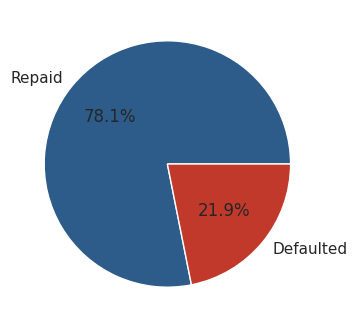

In [4]:
n_def = df.loan_status.sum()
print(f'Default rate: {df.loan_status.mean():.1%}  ({n_def:,} of {len(df):,} loans)')
print(f'Total loan book: {df.loan_amnt.sum():,.0f}   Defaulted amount: {df[df.loan_status==1].loan_amnt.sum():,.0f} ({df[df.loan_status==1].loan_amnt.sum()/df.loan_amnt.sum():.1%})')
df.loan_status.map({0:'Repaid',1:'Defaulted'}).value_counts().plot.pie(autopct='%1.1f%%', colors=['#2E5C8A','#C0392B'], figsize=(4,4)); plt.ylabel(''); plt.show()

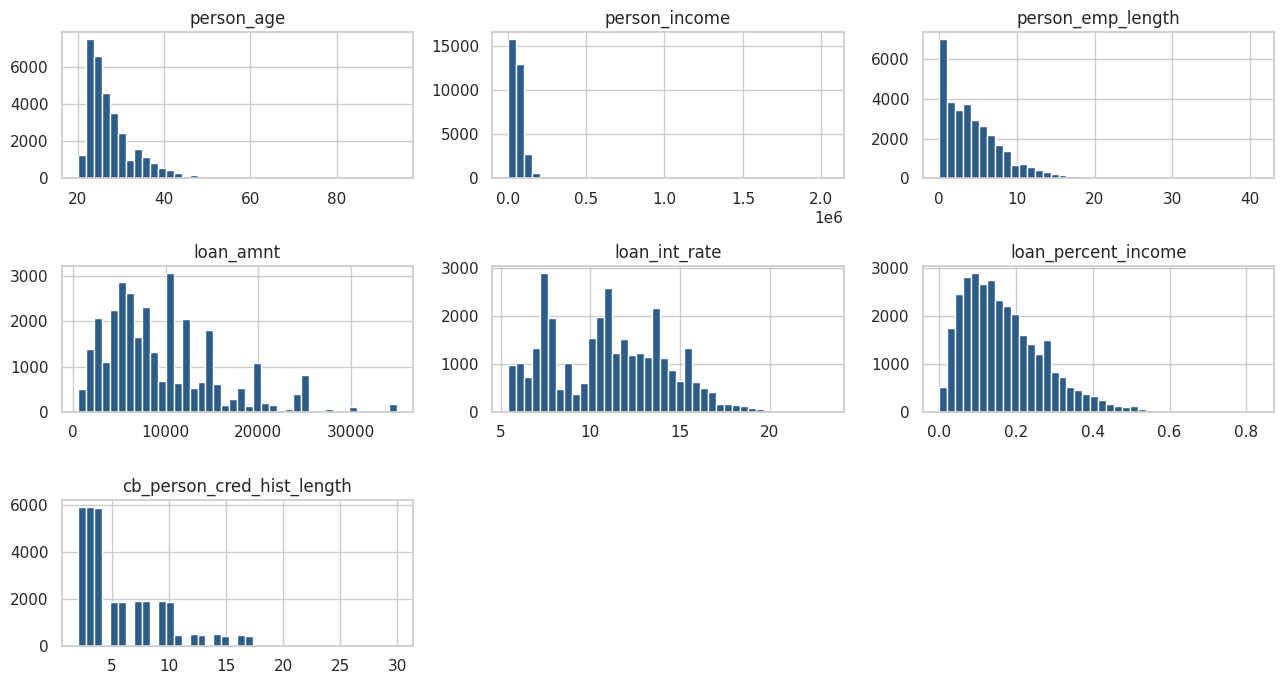

In [5]:
num = ['person_age','person_income','person_emp_length','loan_amnt','loan_int_rate','loan_percent_income','cb_person_cred_hist_length']
df[num].hist(bins=40, figsize=(13,7), color='#2E5C8A'); plt.tight_layout(); plt.show()

## 5. Default patterns by category

In [6]:
def dr(col, order=None):
    t = df.groupby(col, observed=True).loan_status.agg(default_rate='mean', loans='count')
    t['default_rate'] = (t.default_rate*100).round(1); return t
for c in ['loan_grade','person_home_ownership','loan_intent','cb_person_default_on_file']:
    display(dr(c))

,default_rate,loans
loan_grade,,
A,10.0,10703
B,16.3,10384
C,20.8,6436
D,59.1,3620
E,64.5,963
F,70.5,241
G,98.4,64


,default_rate,loans
person_home_ownership,,
MORTGAGE,12.6,13367
OTHER,31.1,106
OWN,7.5,2563
RENT,31.6,16375


,default_rate,loans
loan_intent,,
DEBTCONSOLIDATION,28.7,5189
EDUCATION,17.3,6409
HOMEIMPROVEMENT,26.2,3594
MEDICAL,26.8,6042
PERSONAL,19.9,5497
VENTURE,14.9,5680


,default_rate,loans
cb_person_default_on_file,,
N,18.4,26681
Y,37.9,5730


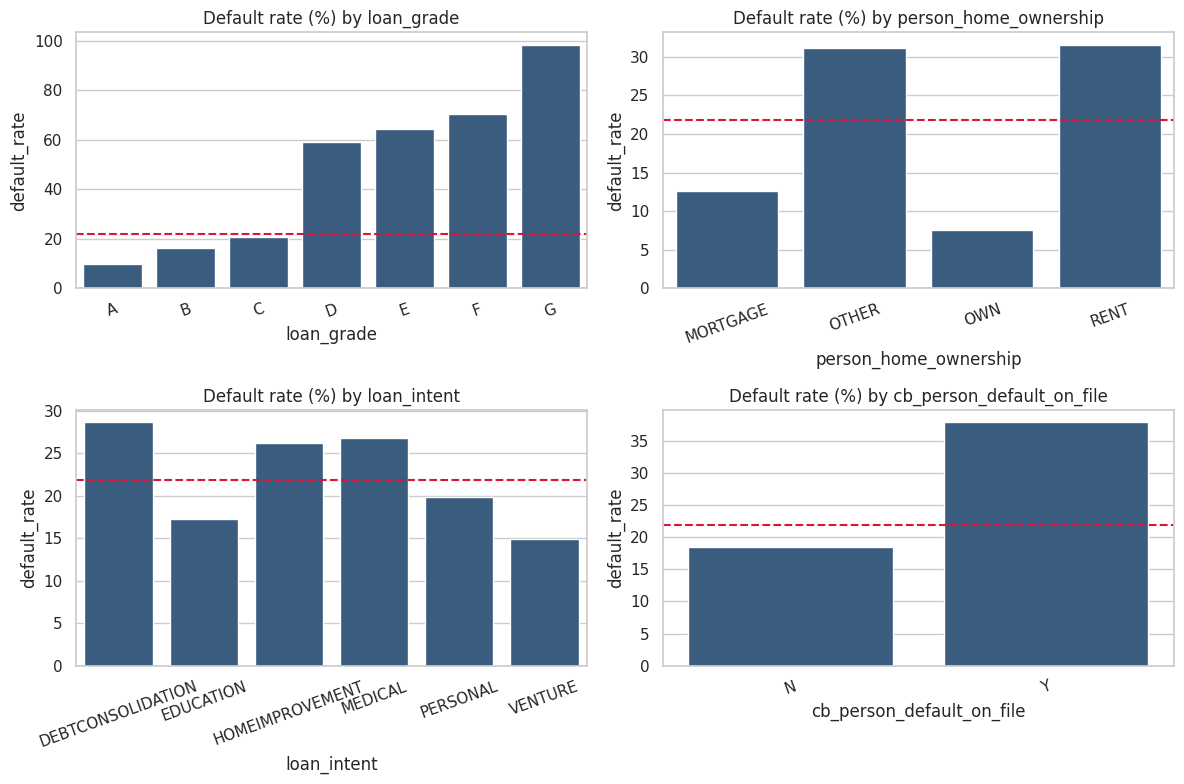

In [7]:
fig, axs = plt.subplots(2,2, figsize=(12,8))
for a,c in zip(axs.flat, ['loan_grade','person_home_ownership','loan_intent','cb_person_default_on_file']):
    t = dr(c); sns.barplot(x=t.index, y=t.default_rate, ax=a, color='#2E5C8A')
    a.axhline(df.loan_status.mean()*100, c='crimson', ls='--'); a.set_title('Default rate (%) by '+c); a.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Reading:** Default climbs steeply with grade (10% for A → ~98% for G). Renters default at 31.6% vs 7.5% for owners. Debt consolidation, medical and home-improvement loans are riskiest; venture and education are the safest. Borrowers with a prior default on file default at 37.9% vs 18.4%.

## 6. Default patterns by numeric bands

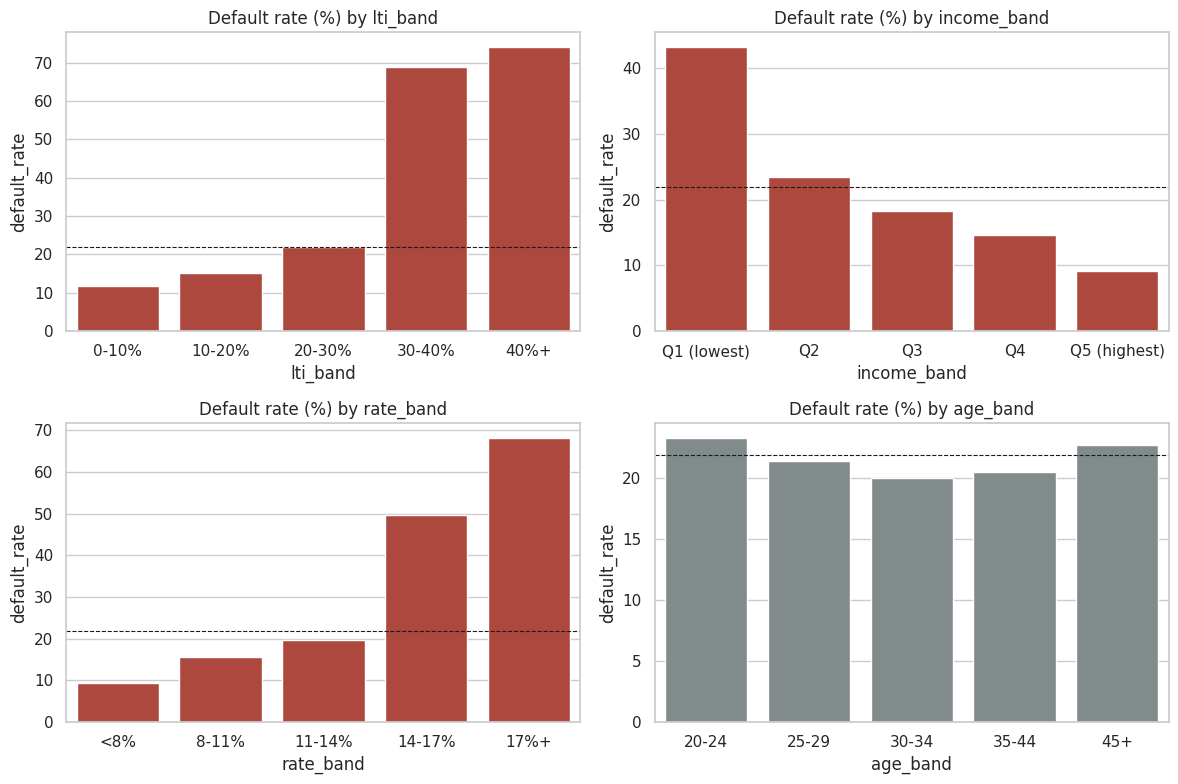

In [8]:
df['income_band'] = pd.qcut(df.person_income, 5, labels=['Q1 (lowest)','Q2','Q3','Q4','Q5 (highest)'])
df['lti_band'] = pd.cut(df.loan_percent_income, [-.01,.1,.2,.3,.4,1], labels=['0-10%','10-20%','20-30%','30-40%','40%+'])
df['rate_band'] = pd.cut(df.loan_int_rate, [0,8,11,14,17,30], labels=['<8%','8-11%','11-14%','14-17%','17%+'])
df['age_band'] = pd.cut(df.person_age, [19,24,29,34,44,100], labels=['20-24','25-29','30-34','35-44','45+'])
fig, axs = plt.subplots(2,2, figsize=(12,8))
for a,c in zip(axs.flat, ['lti_band','income_band','rate_band','age_band']):
    t = dr(c); sns.barplot(x=t.index.astype(str), y=t.default_rate, ax=a, color='#C0392B' if c!='age_band' else '#7F8C8D')
    a.axhline(df.loan_status.mean()*100, c='k', ls='--', lw=.8); a.set_title('Default rate (%) by '+c)
plt.tight_layout(); plt.show()

**Reading:** The jump happens at a loan-to-income ratio of 30% (22% → 69%). Lowest-income quintile defaults at 43% vs 9% for the highest. Rates above 14% are linked to ~50–68% default. Age shows almost no signal.

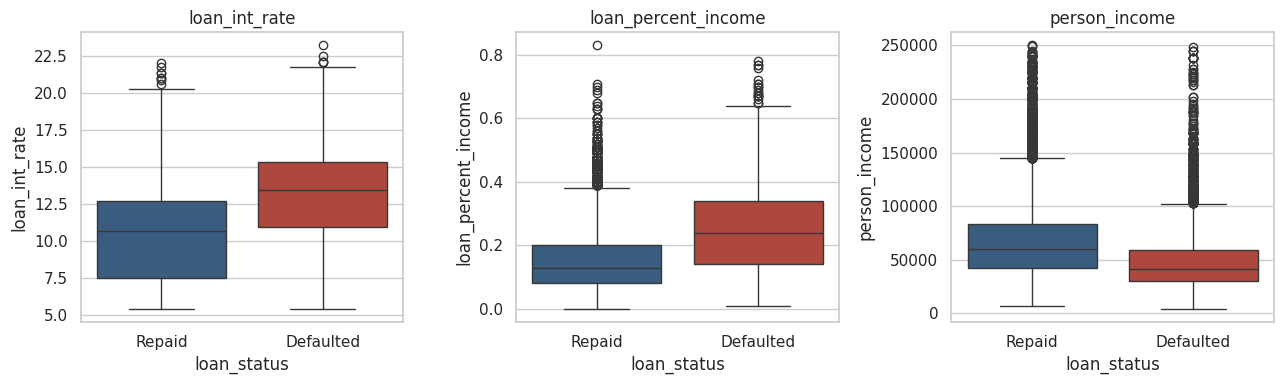

In [9]:
fig, axs = plt.subplots(1,3, figsize=(13,4))
for a,c in zip(axs, ['loan_int_rate','loan_percent_income','person_income']):
    d = df[df.person_income<250000] if c=='person_income' else df
    sns.boxplot(x='loan_status', y=c, data=d, ax=a, palette=['#2E5C8A','#C0392B']); a.set_xticklabels(['Repaid','Defaulted']); a.set_title(c)
plt.tight_layout(); plt.show()

## 7. Correlation & interaction analysis

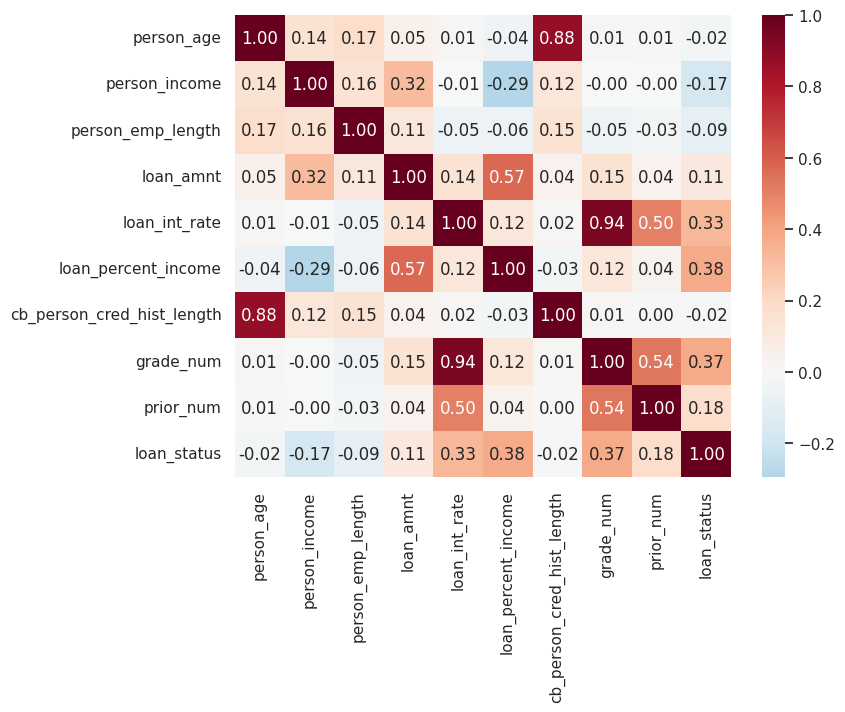

loan_percent_income           0.379704
grade_num                     0.373462
loan_int_rate                 0.334181
prior_num                     0.179354
loan_amnt                     0.105771
cb_person_cred_hist_length   -0.016473
person_age                   -0.021808
person_emp_length            -0.085970
person_income                -0.169284
Name: loan_status, dtype: float64

In [10]:
df['grade_num'] = df.loan_grade.map({g:i for i,g in enumerate('ABCDEFG')}); df['prior_num'] = (df.cb_person_default_on_file=='Y').astype(int)
cm = df[num+['grade_num','prior_num','loan_status']].corr()
plt.figure(figsize=(8,6)); sns.heatmap(cm, annot=True, fmt='.2f', cmap='RdBu_r', center=0); plt.show()
cm['loan_status'].drop('loan_status').sort_values(ascending=False)

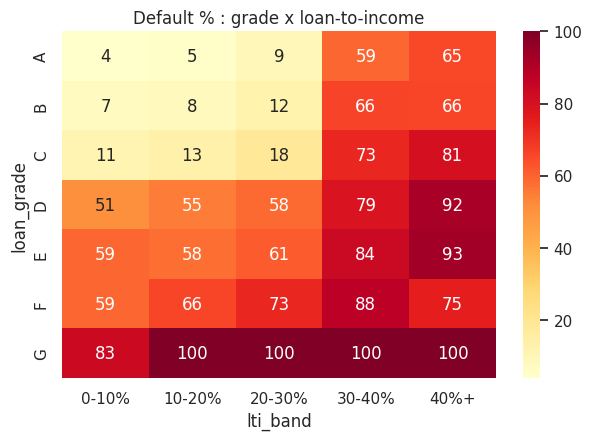

In [11]:
hp = df.pivot_table(index='loan_grade', columns='lti_band', values='loan_status', aggfunc='mean', observed=True)*100
plt.figure(figsize=(7,4.5)); sns.heatmap(hp, annot=True, fmt='.0f', cmap='YlOrRd'); plt.title('Default % : grade x loan-to-income'); plt.show()

## 8. Simple risk scorecard (6 flags)
One point for each: grade D–G · loan ≥30% of income · renter/other · prior default · rate ≥14% · income in bottom quartile.

,default_rate,loans
flags,,
0,4.4,9629
1,7.4,10131
2,28.9,6322
3,57.6,3615
4,66.9,1872
5,87.6,725
6,99.1,117


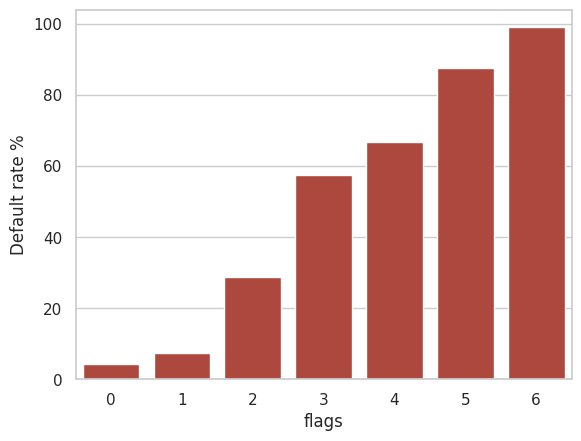

In [12]:
df['flags'] = ((df.grade_num>=3).astype(int) + (df.loan_percent_income>=.30).astype(int) + df.person_home_ownership.isin(['RENT','OTHER']).astype(int)
               + df.prior_num + (df.loan_int_rate>=14).astype(int) + (df.person_income<df.person_income.quantile(.25)).astype(int))
ft = df.groupby('flags').loan_status.agg(default_rate='mean', loans='count'); ft['default_rate']=(ft.default_rate*100).round(1); display(ft)
sns.barplot(x=ft.index, y=ft.default_rate, color='#C0392B'); plt.ylabel('Default rate %'); plt.show()

## 9. Predictive modelling

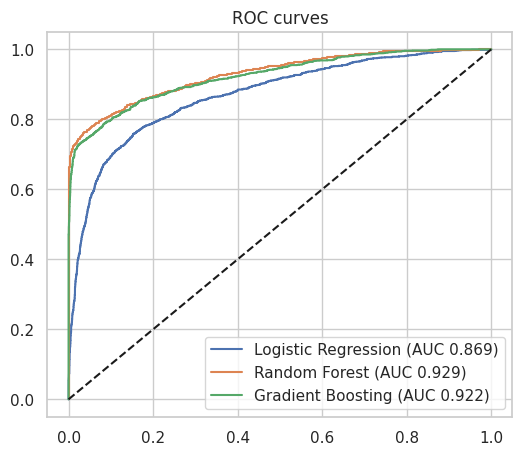

,AUC,Accuracy,Precision,Recall,F1
Logistic Regression,0.869,0.814,0.553,0.778,0.647
Random Forest,0.929,0.924,0.888,0.748,0.812
Gradient Boosting,0.922,0.925,0.934,0.707,0.804


In [13]:
cat = ['person_home_ownership','loan_intent','loan_grade','cb_person_default_on_file']
X = pd.get_dummies(df[num+cat+['emp_length_missing','int_rate_missing']], columns=cat, drop_first=True); y = df.loan_status
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
sc = StandardScaler().fit(Xtr[num]); Xtr_s, Xte_s = Xtr.copy(), Xte.copy(); Xtr_s[num]=sc.transform(Xtr[num]); Xte_s[num]=sc.transform(Xte[num])
models = {'Logistic Regression':(LogisticRegression(max_iter=2000, class_weight='balanced'),True),
          'Random Forest':(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced', random_state=42, n_jobs=-1),False),
          'Gradient Boosting':(GradientBoostingClassifier(random_state=42),False)}
res = {}; plt.figure(figsize=(6,5))
for n,(m,s) in models.items():
    m.fit(Xtr_s if s else Xtr, ytr); p = m.predict_proba(Xte_s if s else Xte)[:,1]; pr = (p>=.5).astype(int)
    res[n] = dict(AUC=roc_auc_score(yte,p), Accuracy=accuracy_score(yte,pr), Precision=precision_score(yte,pr), Recall=recall_score(yte,pr), F1=f1_score(yte,pr))
    f,t,_ = roc_curve(yte,p); plt.plot(f,t,label=f'{n} (AUC {res[n]["AUC"]:.3f})')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.title('ROC curves'); plt.show()
pd.DataFrame(res).T.round(3)

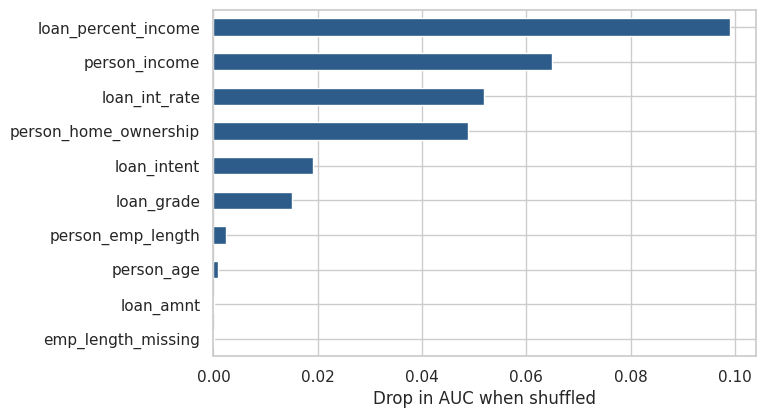

In [14]:
from sklearn.inspection import permutation_importance
gb = models['Gradient Boosting'][0]
pi = permutation_importance(gb, Xte, yte, scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns); g = {}
for c,v in imp.items():
    k = next((x for x in cat if c.startswith(x)), c); g[k] = g.get(k,0)+v
pd.Series(g).sort_values().tail(10).plot.barh(color='#2E5C8A', figsize=(7,4.5)); plt.xlabel('Drop in AUC when shuffled'); plt.show()

## 10. Conclusions
- **21.9%** of loans default; defaulted loans carry ~**24.8%** of the total amount lent.
- The strongest signals are **loan-to-income ratio, loan grade, interest rate, income and home ownership**. Age and credit-history length add almost nothing.
- The 6-flag scorecard separates borrowers cleanly: **4.4%** default with 0 flags vs **99%** with all 6.
- Random Forest / Gradient Boosting reach **AUC ≈ 0.92–0.93**; Logistic Regression **0.87**.

**Caveats:** `loan_grade` and `loan_int_rate` are the lender's own assessment, so they partly encode risk the bank already priced in. The dataset is a cleaned public sample (widely regarded as simulated), so patterns show analytical method more than real-world lending conditions.